# W04 — Dürtü Tepkisi, LCCDE, Kararlılık ve Nedensellik

**Öğrenme Çıktıları**
- $h[n]$ kavramını tanımlar, LCCDE (Linear Constant-Coefficient Difference Equation) $\rightarrow H(z) \rightarrow h[n]$ akışını uygular.
- Nedensellik ve BIBO kararlılığını $h[n]$ üzerinden test eder.
- Fark denklemini iteratif olarak simüle eder.
- Konvolüsyonun temel tanımını bilir: $y[n]=\sum_k x[k]\,h[n-k]$.

## 1) Teori Kısa Notları
- LTI ve dürtü tepkisi ilişkisi; nedensellik: $h[n]=0$ for $n<0$; BIBO: $\sum_n |h[n]|<\infty$.
- LCCDE'den $H(z)=\dfrac{Y(z)}{X(z)}$ ve ters-$z$ ile $h[n]$.

## 2) Örnek-1: 1. Derece Sistemden $h[n]$ Çıkarımı
$$
y[n]-a y[n-1]=x[n] \Rightarrow H(z)=\frac{1}{1-a z^{-1}} \Rightarrow h[n]=a^n u[n]
$$
Aşağıda farklı $a$ değerleri için $h[n]$ örnekleri çizilir.

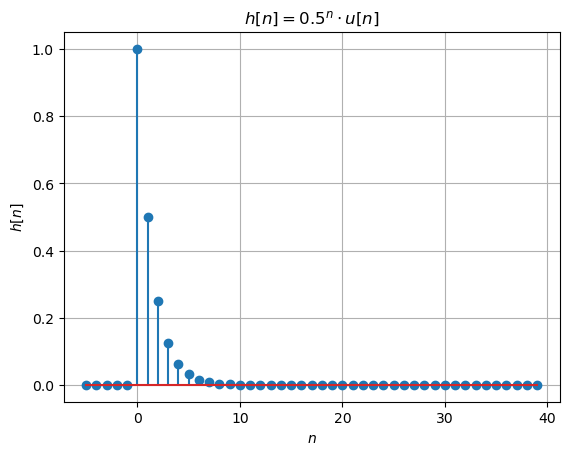

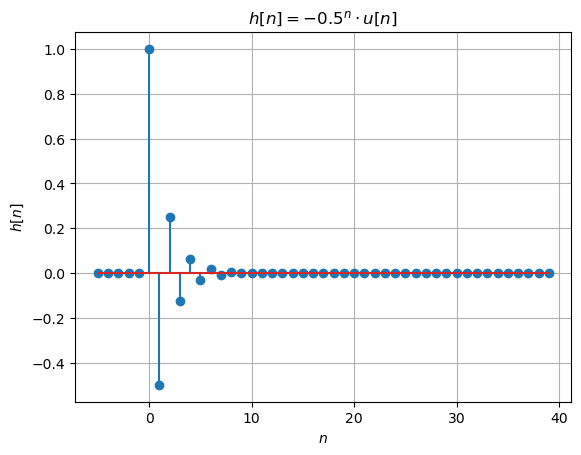

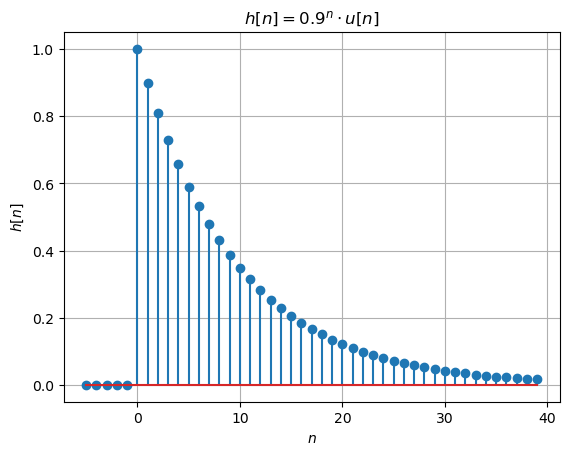

In [3]:
import numpy as np
import matplotlib.pyplot as plt

def u(n):
    return (n>=0).astype(int)

def h_geom(a, n):
    return (a**n) * u(n)

N = 40
n = np.arange(-5, N)
for a in [0.5, -0.5, 0.9]:
    h = h_geom(a, n)
    plt.figure()
    plt.stem(n, h)
    plt.title(rf"$h[n] = {a}^n \cdot u[n]$")
    plt.xlabel(r"$n$")
    plt.ylabel(r"$h[n]$")
    plt.grid(True)


## 3) BIBO Kararlılık Testi
Kararlılık ölçütü: $\sum_n |h[n]|<\infty$. Aşağıda pratik bir yaklaşık test fonksiyonu verilmiştir.

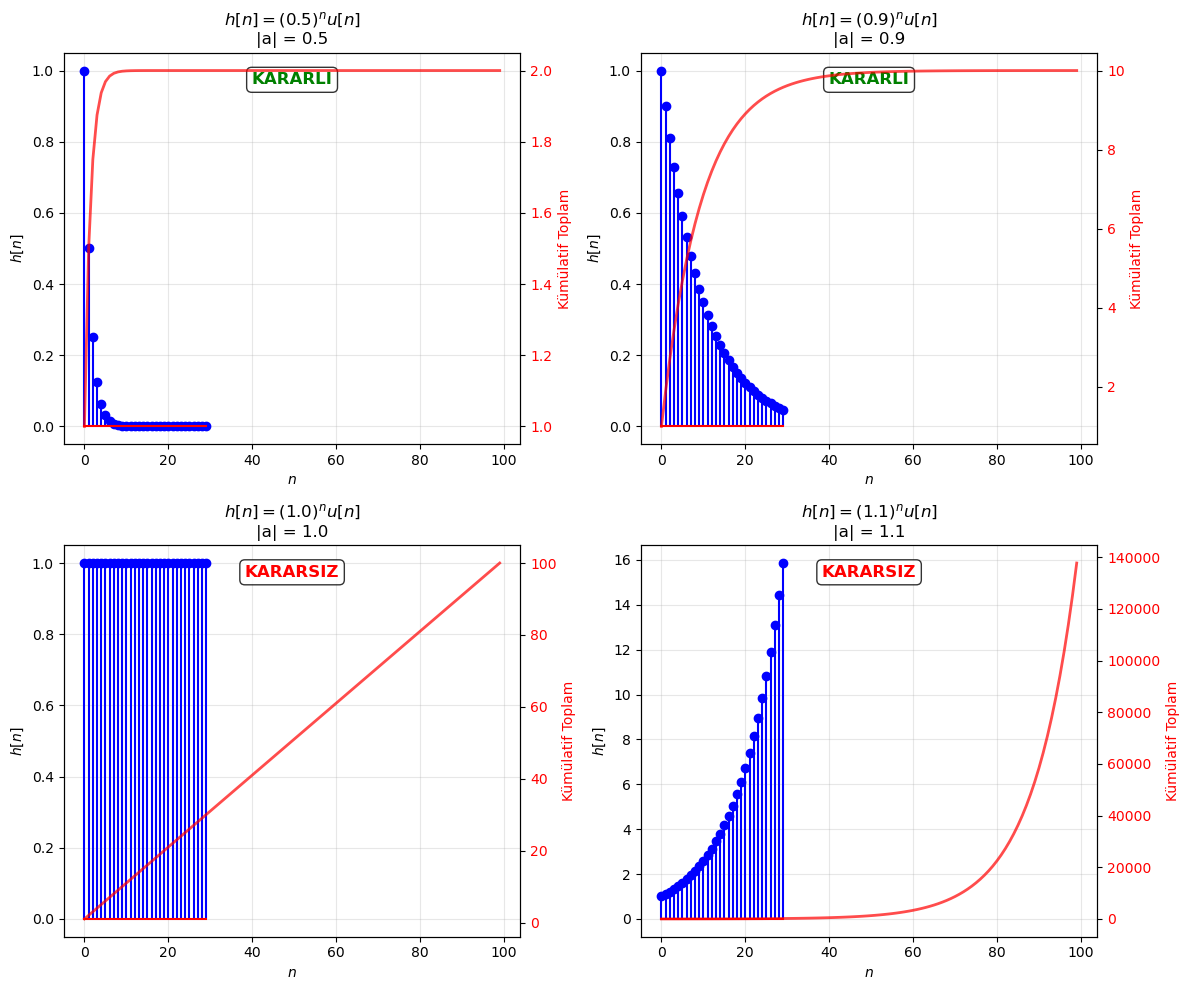

MATEMATİKSEL KRİTER:
|a| < 1 ise: ∑|aⁿ| = 1/(1-|a|) < ∞ → KARARLI
|a| ≥ 1 ise: ∑|aⁿ| = ∞ → KARARSIZ

Sonuçlar:
a = 0.5: |a| = 0.5 < 1 → Kararlı, ∑|aⁿ| = 2.00
a = 0.9: |a| = 0.9 < 1 → Kararlı, ∑|aⁿ| = 10.00
a = 1.0: |a| = 1.0 ≥ 1 → Kararsız, ∑|aⁿ| = ∞
a = 1.1: |a| = 1.1 ≥ 1 → Kararsız, ∑|aⁿ| = ∞


In [156]:
def analyze_stability(a_values, n_points=100):
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    axes = axes.flatten()
    
    for i, a in enumerate(a_values):
        n = np.arange(0, n_points)
        h = a**n
        cumulative = np.cumsum(np.abs(h))
        
        # Dürtü tepkisi
        axes[i].stem(n[:30], h[:30], linefmt='b-', markerfmt='bo', basefmt='r-')
        axes[i].set_title(f'$h[n] = ({a})^n u[n]$\n|a| = {abs(a):.1f}')
        axes[i].set_xlabel('$n$')
        axes[i].set_ylabel('$h[n]$')
        axes[i].grid(True, alpha=0.3)
        
        # Kümülatif toplam (ikinci eksen)
        ax2 = axes[i].twinx()
        ax2.plot(n, cumulative, 'r-', linewidth=2, alpha=0.7)
        ax2.set_ylabel('Kümülatif Toplam', color='r')
        ax2.tick_params(axis='y', labelcolor='r')
        
        # Kararlılık durumu
        math_stable = abs(a) < 1
        status = "KARARLI" if math_stable else "KARARSIZ"
        axes[i].text(0.5, 0.95, status, transform=axes[i].transAxes, 
                    fontsize=12, weight='bold', color='green' if math_stable else 'red',
                    ha='center', va='top', bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))
    
    plt.tight_layout()
    plt.show()

# Analiz
a_values = [0.5, 0.9, 1.0, 1.1]
analyze_stability(a_values)

print("MATEMATİKSEL KRİTER:")
print("|a| < 1 ise: ∑|aⁿ| = 1/(1-|a|) < ∞ → KARARLI")
print("|a| ≥ 1 ise: ∑|aⁿ| = ∞ → KARARSIZ")
print("\nSonuçlar:")
for a in a_values:
    stable = abs(a) < 1
    if stable:
        theoretical_sum = 1 / (1 - abs(a))
        print(f"a = {a}: |a| = {abs(a)} < 1 → Kararlı, ∑|aⁿ| = {theoretical_sum:.2f}")
    else:
        print(f"a = {a}: |a| = {abs(a)} ≥ 1 → Kararsız, ∑|aⁿ| = ∞")

## 4) Nedensellik Testi
Nedensellik: $n<0$ için $h[n]=0$.

Causal? True
Causal? False


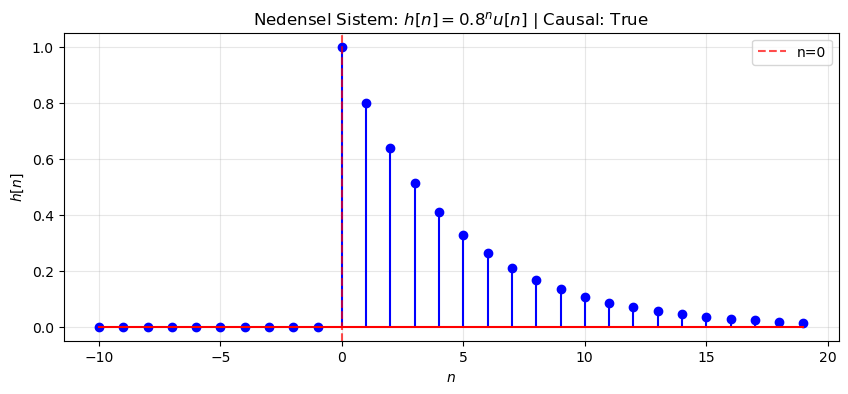

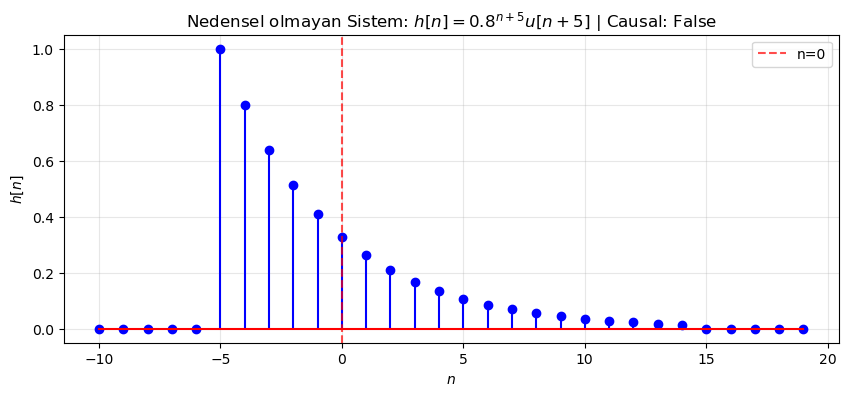

In [150]:
def is_causal(n_axis, h_vals):
    return np.all(h_vals[n_axis < 0] == 0)

def plot_signal(n, h, title, causal_status):
    plt.figure(figsize=(10, 4))
    plt.stem(n, h, linefmt='b-', markerfmt='bo', basefmt='r-')
    plt.axvline(x=0, color='red', linestyle='--', alpha=0.7, label='n=0')
    plt.title(rf'{title} | Causal: {causal_status}') 
    plt.xlabel('$n$')
    plt.ylabel('$h[n]$')
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

# Sinyalleri oluştur
n = np.arange(-10, 20)
h_causal = (0.8**n) * (n>=0)
h_noncausal = np.roll(h_causal, -5)

# Causal mi değil mi kontrol et
causal_status1 = is_causal(n, h_causal)
causal_status2 = is_causal(n, h_noncausal)

print("Causal?", causal_status1)
print("Causal?", causal_status2)

# Sinyalleri çizdir
plot_signal(n, h_causal, r'Nedensel Sistem: $h[n] = 0.8^n u[n]$', causal_status1)
plot_signal(n, h_noncausal, r'Nedensel olmayan Sistem: $h[n] = 0.8^{n+5} u[n+5]$', causal_status2)

## 5) Fark Denklemini İteratif Çözmek (Konvolüsyon Kullanmadan)
Başlangıç koşulu $y[-1]=0$. Girdi olarak $\delta[n]$ ve $u[n]$ denenir. Grafikler **ayrı eksenlerde** çizilir.

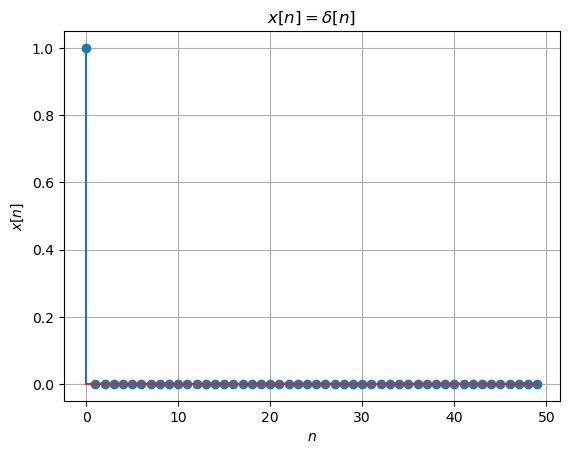

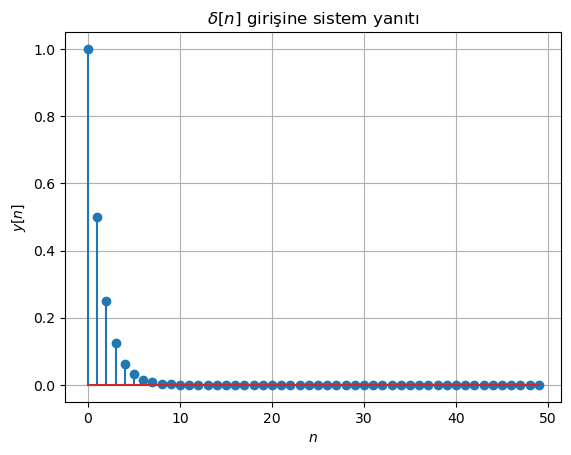

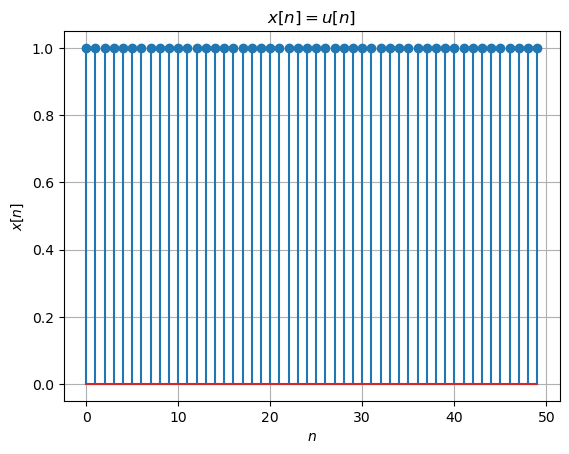

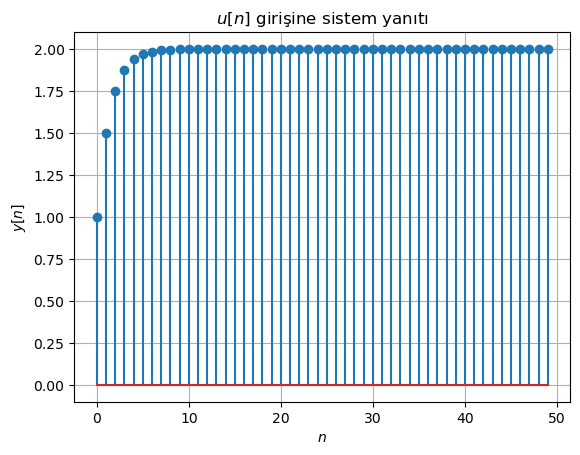

In [147]:
def simulate_first_order(a, x, y_init=0.0):
    y = np.zeros_like(x, dtype=float)
    y_prev = y_init
    for i in range(len(x)):
        y[i] = a * y_prev + x[i]
        y_prev = y[i]
    return y

N = 50
n = np.arange(0, N)
delta = np.zeros(N); delta[0]=1
step = np.ones(N)
a = 0.5

y_delta = simulate_first_order(a, delta)
y_step = simulate_first_order(a, step)

plt.figure(); plt.stem(n, delta); plt.title(r"$x[n] = \delta[n]$"); plt.xlabel(r"$n$"); plt.ylabel(r"$x[n]$"); plt.grid(True)
plt.figure(); plt.stem(n, y_delta); plt.title(r"$\delta[n]$ girişine sistem yanıtı"); plt.xlabel(r"$n$"); plt.ylabel(r"$y[n]$"); plt.grid(True)
plt.figure(); plt.stem(n, step); plt.title(r"$x[n] = u[n]$"); plt.xlabel(r"$n$"); plt.ylabel(r"$x[n]$"); plt.grid(True)
plt.figure(); plt.stem(n, y_step); plt.title(r"$u[n]$ girişine sistem yanıtı"); plt.xlabel(r"$n$"); plt.ylabel(r"$y[n]$"); plt.grid(True)


## 6) Mini Blok-Şema
- Gecikme bloğu: $z^{-1}$
- Ölçekleme: sabit katsayı ile çarpma
- Toplayıcı: çoklu sinyal girişini toplar

1. Derece örnek: $y[n]=a\,y[n-1]+x[n]$. Bu yapı, bir adet $z^{-1}$ gecikme ve iki toplama yolundan oluşur.

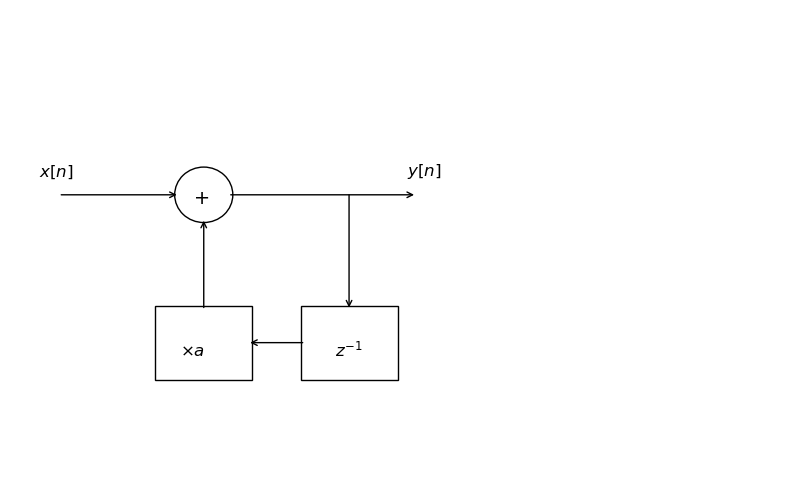

In [167]:
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(10, 6))
ax.set_xlim(0, 8)
ax.set_ylim(0, 5)
ax.axis('off')

# x[n] input → adder
ax.annotate('', xy=(1.75, 3), xytext=(0.5, 3), arrowprops=dict(arrowstyle='->'))
ax.text(0.3, 3.2, r"$x[n]$", fontsize=12)

# Adder (⊕)
adder = patches.Circle((2, 3), 0.3, fill=False)
ax.add_patch(adder)
ax.text(1.90, 2.9, '+', fontsize=14)

# Output y[n]
ax.annotate('', xy=(4.2, 3), xytext=(2.25, 3), arrowprops=dict(arrowstyle='->'))
ax.text(4.1, 3.2, r"$y[n]$", fontsize=12)

# y[n] → downward to z⁻¹
ax.annotate('', xy=(3.5, 3.03), xytext=(3.5, 1.75), arrowprops=dict(arrowstyle='<-'))

# z⁻¹ block
z1 = patches.Rectangle((3.0, 1), 1, 0.8, fill=False)
ax.add_patch(z1)
ax.text(3.35, 1.25, r"$z^{-1}$", fontsize=12)

# z⁻¹ → a
ax.annotate('', xy=(2.45, 1.4), xytext=(3.05, 1.4), arrowprops=dict(arrowstyle='->'))

# a block
a_block = patches.Rectangle((1.5, 1), 1, 0.8, fill=False)
ax.add_patch(a_block)
ax.text(1.75, 1.25, r"$\times a$", fontsize=12)

# a → upward to adder
ax.annotate('', xy=(2, 1.75), xytext=(2, 2.75), arrowprops=dict(arrowstyle='<-'))
plt.show()

## 7) Kısa Alıştırmalar
- A1) $y[n]-0.8y[n-1]+0.16y[n-2]=x[n]$: $h[n]$ ve kararlılık.
- A2) $h[n]=(-1)^n u[n]$: nedensellik ve kararlılık yorumu.
- A3) $y[n]=x[n]-x[n-1]$: $h[n]$ ve basamak girişine yanıt.
- A4) $y[n]-0.8y[n-1]+0.16y[n-2]=x[n]$ için iteratif çözümle $x[n]=u[n]$ için $y[n]$ üret ($a=0.5$).